# 02 — Baseline: XLM-RoBERTa-base (multi-head)
**Goal:** fine-tune `xlm-roberta-base` with three heads (category 11, secondary 12 including `none`,
urgency 2) on a shared backbone.

**Runtime:** Colab **GPU (T4)**. Requires notebook 01 to have been run (processed splits + `data_config.json`).

Checkpoints go to Drive after **every epoch** (`checkpoints/xlmr-base/last.pt`). If Colab disconnects,
re-run this notebook and training resumes where it stopped.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 2.1 Setup

In [2]:
# --- Environment setup (Colab or local) -------------------------------------------------
import os, sys, json, subprocess
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = Path("/content/drive/MyDrive/TensorForge/training")   # upload the `training/` folder here
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(ROOT / "requirements-colab.txt")], check=True)
else:
    ROOT = Path.cwd().resolve().parent                  # training/notebooks -> training/

sys.path.insert(0, str(ROOT / "src"))
from tfml.paths import Paths
P = Paths(ROOT)
print("ROOT:", P.root, "| raw data:", P.raw_data)

import numpy as np, pandas as pd, torch, matplotlib.pyplot as plt, seaborn as sns
from tfml import data as D, engine as E, metrics as M
from tfml.labels import CATEGORIES
print("torch", torch.__version__, "| CUDA:", torch.cuda.is_available(),
      torch.cuda.get_device_name(0) if torch.cuda.is_available() else "")
assert torch.cuda.is_available(), "Switch to a GPU runtime (Runtime -> Change runtime type -> T4 GPU)"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
ROOT: /content/drive/MyDrive/TensorForge/training | raw data: /content/drive/MyDrive/TensorForge/training/data
torch 2.11.0+cu130 | CUDA: True Tesla T4


## 2.2 Load data (processed in notebook 01)

In [3]:
splits = D.load_processed(P)
data_config = json.loads(P.data_config.read_text())
print({k: len(v) for k, v in splits.items()}, data_config)

{'train': 3600, 'dev': 400, 'val': 800} {'max_length': 192, 'token_p995': 188.0050000000001, 'dev_frac': 0.1, 'seed': 42, 'n_train': 3600, 'n_dev': 400, 'n_val': 800}


## 2.3–2.6 Label encoding, tokenization, dataset, model
These live in `src/tfml/` so notebook 03 reuses the exact same pipeline:
- `data.encode_labels`: category → 0..10, secondary → 0..11 (11 = `none`), urgency → 0/1
- `data.TicketDataset` / `make_collate`: sentence-pair tokenization with `truncation="only_second"`
  and dynamic padding
- `modeling.MultiHeadClassifier`: backbone → `[CLS]` → dropout → 3 linear heads

In [4]:
from tfml.modeling import build_model
_m, _tok = build_model("xlmr-base")
ex = D.TicketDataset(_tok, splits["train"].head(2), data_config["max_length"])[0]
print(_tok.decode(ex["input_ids"])[:300])
print({k: v for k, v in ex.items() if k != "input_ids" and k != "attention_mask"})
print(f"params: {sum(p.numel() for p in _m.parameters()) / 1e6:.1f}M")
del _m

config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.12GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaModel LOAD REPORT from: FacebookAI/xlm-roberta-base
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.weight | UNEXPECTED |  | 
lm_head.layer_norm.weight   | UNEXPECTED |  | 
roberta.pooler.dense.bias   | UNEXPECTED |  | 
lm_head.layer_norm.bias     | UNEXPECTED |  | 
lm_head.dense.bias          | UNEXPECTED |  | 
lm_head.dense.weight        | UNEXPECTED |  | 
lm_head.bias                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


<s> email</s> Please check this</s></s> dear rideeat suport, the amount shown in the record was 1.5k rupees. i have checked the details again before sending this. i am giving as much background as i can remember so the record can be located. i do not remember the exact minute i opened the service, b
{'category_label': 3, 'secondary_label': 11, 'urgency_label': 0}
params: 277.5M


## 2.7–2.8 Loss and training
`L = 1.0·CE_category + 0.5·CE_secondary + 0.3·CE_urgency`. AdamW, linear warmup (10%), fp16 autocast,
grad-clip 1.0. The best epoch is chosen by **dev** category macro-F1, not validation (amended plan).

In [5]:
cfg = E.TrainConfig(
    model_key="xlmr-base",
    learning_rate=2e-5,
    batch_size=16,              # T4 16 GB: fits comfortably with fp16
    max_length=data_config["max_length"],
    epochs=5,
    warmup_ratio=0.1,
    weight_decay=0.01,
    loss_weights=(1.0, 0.5, 0.3),
)
print(cfg)
result = E.train_model(cfg, splits, P.checkpoints, resume=True)

TrainConfig(model_key='xlmr-base', learning_rate=2e-05, batch_size=16, max_length=192, epochs=5, warmup_ratio=0.1, weight_decay=0.01, loss_weights=(1.0, 0.5, 0.3), dropout=0.1, grad_clip=1.0, fp16=True, seed=42, eval_batch_size=64)


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaModel LOAD REPORT from: FacebookAI/xlm-roberta-base
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.weight | UNEXPECTED |  | 
lm_head.layer_norm.weight   | UNEXPECTED |  | 
roberta.pooler.dense.bias   | UNEXPECTED |  | 
lm_head.layer_norm.bias     | UNEXPECTED |  | 
lm_head.dense.bias          | UNEXPECTED |  | 
lm_head.dense.weight        | UNEXPECTED |  | 
lm_head.bias                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
/content/drive/MyDrive/TensorForge/training/src/tfml/engine.py:158: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more det

  epoch 1 step 50/225 loss 3.7882
  epoch 1 step 100/225 loss 3.2827
  epoch 1 step 150/225 loss 2.9918
  epoch 1 step 200/225 loss 2.6592
epoch 1: loss 2.5031 | dev cat acc 0.7625 macroF1 0.6316 | sec F1 0.0000 | urg F1 0.0000 | 50.0s
  -> new best, saved to /content/drive/MyDrive/TensorForge/training/checkpoints/xlmr-base/best
  epoch 2 step 50/225 loss 0.9804
  epoch 2 step 100/225 loss 0.8227
  epoch 2 step 150/225 loss 0.7217
  epoch 2 step 200/225 loss 0.6456
epoch 2: loss 0.6133 | dev cat acc 0.9875 macroF1 0.9855 | sec F1 0.0625 | urg F1 0.5294 | 51.0s
  -> new best, saved to /content/drive/MyDrive/TensorForge/training/checkpoints/xlmr-base/best
  epoch 3 step 50/225 loss 0.2552
  epoch 3 step 100/225 loss 0.2464
  epoch 3 step 150/225 loss 0.2259
  epoch 3 step 200/225 loss 0.2035
epoch 3: loss 0.1975 | dev cat acc 0.9925 macroF1 0.9886 | sec F1 0.8571 | urg F1 0.6757 | 52.6s
  -> new best, saved to /content/drive/MyDrive/TensorForge/training/checkpoints/xlmr-base/best
  epoch

In [ ]:
hist = pd.DataFrame(result["history"]).set_index("epoch")
print(hist[["train_loss", "dev_category_acc", "dev_category_macro_f1", "dev_secondary_f1", "dev_urgency_f1"]].round(4).to_string())
hist[["dev_category_macro_f1", "dev_secondary_f1", "dev_urgency_f1"]].plot(marker="o", figsize=(8, 4), title="dev metrics per epoch")
plt.savefig(P.figures / "2_training_curve_xlmr.png", dpi=120); plt.show()

## 2.9 Validation (held-out), best checkpoint
Validation is scored **once**, with the best dev checkpoint and default decoding (argmax, urgency 0.5).
Calibration and thresholds are tuned in notebook 04 on dev only.

In [6]:
val_df, val_dec = splits["val"], result["val_decoded"]
print(json.dumps({k: round(v, 4) for k, v in result["val"].items()}, indent=1))
print(M.category_report(val_df, val_dec).round(3).to_string())

{
 "n": 800,
 "category_acc": 0.8087,
 "category_macro_f1": 0.8136,
 "category_weighted_f1": 0.8153,
 "secondary_acc": 0.98,
 "secondary_precision": 0.9848,
 "secondary_recall": 0.8125,
 "secondary_f1": 0.8904,
 "urgency_acc": 0.9888,
 "urgency_precision": 0.9494,
 "urgency_recall": 0.9375,
 "urgency_f1": 0.9434,
 "exact_match": 0.7937,
 "ece": 0.1264,
 "mean_confidence": 0.9341
}
                     precision  recall  f1-score  support
payment_refund           0.899   0.743     0.814  144.000
ride_trip_issue          0.954   0.929     0.941  112.000
lost_item                0.892   0.825     0.857   40.000
order_missing_wrong      0.621   0.906     0.737   96.000
delivery_delay           0.805   0.758     0.781  120.000
food_quality             0.930   0.714     0.808   56.000
account_promo            0.984   0.875     0.926   72.000
safety_conduct           1.000   0.906     0.951   32.000
app_technical            0.755   0.625     0.684   64.000
general_inquiry          0.474   0.9

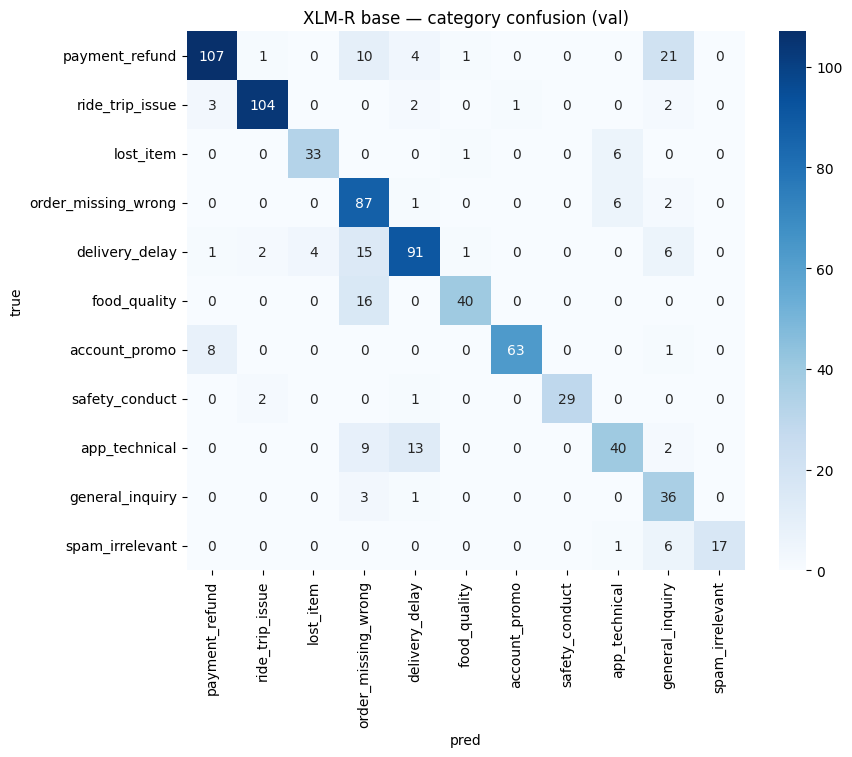

            n  category_acc  category_macro_f1  secondary_acc  urgency_f1  gap_vs_en
language                                                                            
en        280         0.836              0.838          0.968       0.926      0.000
singlish  200         0.675              0.706          0.975       0.947     -0.161
si        160         0.856              0.751          0.994       0.941      0.021
ta        120         0.917              0.882          1.000       1.000      0.081
mixed      20         0.850              0.774          0.950       1.000      0.014
tanglish   20         0.700              0.800          1.000       0.667     -0.136


In [7]:
cm = M.category_confusion(val_df, val_dec)
plt.figure(figsize=(9, 7)); sns.heatmap(cm, annot=True, fmt="d", cmap="Blues"); plt.title("XLM-R base — category confusion (val)")
plt.ylabel("true"); plt.xlabel("pred"); plt.savefig(P.figures / "2_confusion_xlmr.png", dpi=120, bbox_inches="tight"); plt.show()
print(M.per_language(val_df, val_dec).round(3).to_string())

## 2.10 Business rules
`rules.decode_arrays` masks the primary category out of the secondary head *before* choosing, and forces
`spam → is_urgent=False, secondary=None`. `rules.apply_business_rules` then adds `team` (and acts as a
defensive second pass). We assert zero contract violations.

In [8]:
from tfml.rules import to_records, check_consistency
recs = to_records(val_dec, val_df.ticket_id.tolist())
violations = check_consistency(recs)
print("consistency violations:", len(violations)); assert not violations
pd.DataFrame(recs).head()

consistency violations: 0


,ticket_id,category,secondary_category,is_urgent,confidence,needs_human_review,team
0,TF-VA-000432,payment_refund,None,False,0.788491,False,Payments & Refunds
1,TF-VA-000795,payment_refund,ride_trip_issue,False,0.998439,False,Payments & Refunds
2,TF-VA-000262,food_quality,None,True,0.942892,False,Restaurant Quality
3,TF-VA-000665,app_technical,None,False,0.996637,False,Tech Support
4,TF-VA-000423,payment_refund,None,False,0.998069,False,Payments & Refunds


## 2.11 Save baseline metrics

In [9]:
from tfml.engine import dir_size_mb
out = {"model": "xlmr-base", "best_epoch": result["best"]["epoch"], "train_config": cfg.__dict__,
       "dev": result["dev"], "val": result["val"],
       "val_per_language": M.per_language(val_df, val_dec).reset_index().to_dict(orient="records"),
       "checkpoint_mb": dir_size_mb(result["out_dir"] / "best" / "model.pt")}
(P.results / "xlmr-base_metrics.json").write_text(json.dumps(out, indent=2, default=str))
pd.DataFrame(result["history"]).to_csv(P.results / "xlmr-base_history.csv", index=False)
print("saved", P.results / "xlmr-base_metrics.json")
del result; torch.cuda.empty_cache()

saved /content/drive/MyDrive/TensorForge/training/results/xlmr-base_metrics.json
